# 01 Manual EDA – Pima Diabetes Dataset

## 1. Objective

This notebook performs manual exploratory data analysis (EDA) for the **Pima Diabetes** dataset using the standardised research pipeline structure developed from the German Credit reference pipeline.

The purpose of this notebook is to:

- inspect the structure and quality of the raw dataset;
- validate the target variable and modelling objective;
- identify missing values, duplicate records, and implausible clinical zero values;
- create a feature audit table for later preprocessing and explainability work;
- document assumptions clearly for dissertation traceability;
- save all EDA outputs into a standard result folder.

This notebook does **not** perform preprocessing or model training. Those steps are handled in later notebooks.

## 2. Dissertation Alignment

This notebook supports the dissertation pipeline on responsible machine learning and explainable AI in high-stakes decision systems.

For the Pima Diabetes dataset, the high-stakes decision context is **clinical risk prediction**, where the modelling task is to predict whether a patient is likely to have diabetes.

The EDA stage is important because later explainability, counterfactual recourse, and EES scoring depend on clear understanding of:

- feature quality;
- target definition;
- missingness patterns;
- clinically implausible values;
- sensitive or quasi-sensitive variables;
- mutable and non-mutable features;
- assumptions that affect preprocessing and downstream model interpretation.

In [22]:
# =========================================================
# 3. Project Setup and Path Configuration
# =========================================================

from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

try:
    from google.colab import drive
    drive.mount('/content/drive')
except Exception as e:
    print("Google Drive mount skipped or unavailable:", e)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Master research root
ROOT_PATH = Path("/content/drive/MyDrive/Master_Research")

# Dataset and notebook identifiers
DATASET_NAME = "pima_diabetes"
NOTEBOOK_NAME = "01_manual_eda_pima_diabetes"

# Standard paths
DATA_PATH = ROOT_PATH / "04_Data" / DATASET_NAME
RESULTS_PATH = ROOT_PATH / "07_Results" / DATASET_NAME / NOTEBOOK_NAME

TABLES_PATH = RESULTS_PATH / "tables"
FIGURES_PATH = RESULTS_PATH / "figures"
LOGS_PATH = RESULTS_PATH / "logs"

for path in [RESULTS_PATH, TABLES_PATH, FIGURES_PATH, LOGS_PATH]:
    path.mkdir(parents=True, exist_ok=True)

print("Project setup complete.")
print(f"ROOT_PATH:    {ROOT_PATH}")
print(f"DATA_PATH:    {DATA_PATH}")
print(f"RESULTS_PATH: {RESULTS_PATH}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project setup complete.
ROOT_PATH:    /content/drive/MyDrive/Master_Research
DATA_PATH:    /content/drive/MyDrive/Master_Research/04_Data/pima_diabetes
RESULTS_PATH: /content/drive/MyDrive/Master_Research/07_Results/pima_diabetes/01_manual_eda_pima_diabetes


## 4. Key Assumptions

The following assumptions are applied at the EDA stage:

| Area | Assumption | Reason |
|---|---|---|
| Dataset | Pima Diabetes is treated as a binary clinical risk dataset | The target represents diabetes outcome status |
| Target | `Outcome` is the target variable where `1 = diabetes` and `0 = no diabetes` | This is the standard coding used in the common Pima dataset |
| Clinical zero values | Zero values in `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, and `BMI` are treated as implausible clinical missingness indicators | These measurements cannot realistically be zero for living patients |
| Pregnancies | Zero is valid for `Pregnancies` | A person can have zero pregnancies |
| Age | Age is treated as non-mutable | It cannot be changed by a patient |
| Clinical features | Features such as glucose, BMI, insulin, and blood pressure may be clinically actionable or partially mutable | They can potentially change through treatment, behaviour, or medical intervention |
| EDA role | This notebook only diagnoses data issues; it does not impute, scale, encode, or train models | Preprocessing is handled in Notebook 02 |

In [23]:
# =========================================================
# 5. Helper Functions
# =========================================================

def save_df(df, filename, index=False):
    output_path = TABLES_PATH / filename
    df.to_csv(output_path, index=index)
    print(f"Saved: {output_path}")
    return output_path


def save_excel(dfs, filename):
    output_path = TABLES_PATH / filename
    with pd.ExcelWriter(output_path, engine="openpyxl") as writer:
        for sheet_name, df in dfs.items():
            safe_sheet = sheet_name[:31]
            df.to_excel(writer, sheet_name=safe_sheet, index=False)
    print(f"Saved: {output_path}")
    return output_path


def clean_column_names(df):
    df = df.copy()
    df.columns = (
        df.columns
        .str.strip()
        .str.replace(" ", "_", regex=False)
        .str.replace("-", "_", regex=False)
        .str.replace("/", "_", regex=False)
    )
    return df


def find_data_file(data_path):
    candidate_files = [
        "diabetes.csv",
        "pima_diabetes.csv",
        "pima_diabetes_data.csv",
        "pima-indians-diabetes.csv",
        "pima_indians_diabetes.csv",
    ]

    for filename in candidate_files:
        candidate = data_path / filename
        if candidate.exists():
            return candidate

    csv_files = list(data_path.glob("*.csv"))
    if len(csv_files) == 1:
        return csv_files[0]

    if len(csv_files) > 1:
        print("Multiple CSV files found:")
        for file in csv_files:
            print("-", file.name)
        raise FileNotFoundError(
            "Multiple CSV files found. Please set DATA_FILE manually to the correct file."
        )

    raise FileNotFoundError(
        f"No CSV file found in {data_path}. Please place the Pima Diabetes CSV file in this folder."
    )

In [24]:
# =========================================================
# 6. Load Raw Pima Diabetes Dataset
# =========================================================

RAW_DATA_PATH = ROOT_PATH / "04_Data" / "01_Raw_Data" / "pima_diabetes" / "diabetes.csv"

if not RAW_DATA_PATH.exists():
    raise FileNotFoundError(f"Raw diabetes dataset not found at: {RAW_DATA_PATH}")

df_raw = pd.read_csv(RAW_DATA_PATH)

print("Pima Diabetes dataset loaded successfully.")
print(f"Dataset path: {RAW_DATA_PATH}")
print(f"Shape: {df_raw.shape}")

display(df_raw.head())

Pima Diabetes dataset loaded successfully.
Dataset path: /content/drive/MyDrive/Master_Research/04_Data/01_Raw_Data/pima_diabetes/diabetes.csv
Shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [25]:
# =========================================================
# 7. Standardise Target Column
# =========================================================

# Common target names across versions of the Pima dataset
possible_target_columns = ["Outcome", "outcome", "target", "class", "diabetes"]

target_column = None

for col in possible_target_columns:
    if col in df_raw.columns:
        target_column = col
        break

if target_column is None:
    raise ValueError(
        f"Could not identify target column. Available columns: {df_raw.columns.tolist()}"
    )

if target_column != "Outcome":
    df_raw = df_raw.rename(columns={target_column: "Outcome"})
    target_column = "Outcome"

# Ensure target is integer-coded
df_raw[target_column] = df_raw[target_column].astype(int)

print("Target column:", target_column)
print("Target values:", sorted(df_raw[target_column].unique().tolist()))

display(df_raw[target_column].value_counts(dropna=False).rename_axis("Outcome").reset_index(name="count"))

Target column: Outcome
Target values: [0, 1]


,Outcome,count
0,0,500
1,1,268


In [26]:
# =========================================================
# 8. Basic Dataset Overview
# =========================================================

overview_df = pd.DataFrame({
    "metric": [
        "n_rows",
        "n_columns",
        "n_duplicate_rows",
        "n_missing_cells",
        "target_column",
        "target_unique_values",
        "positive_class_rate",
        "negative_class_rate"
    ],
    "value": [
        df_raw.shape[0],
        df_raw.shape[1],
        df_raw.duplicated().sum(),
        df_raw.isna().sum().sum(),
        target_column,
        sorted(df_raw[target_column].unique().tolist()),
        df_raw[target_column].mean(),
        1 - df_raw[target_column].mean()
    ]
})

display(overview_df)
save_df(overview_df, "dataset_overview.csv")

,metric,value
0,n_rows,768
1,n_columns,9
2,n_duplicate_rows,0
3,n_missing_cells,0
4,target_column,Outcome
5,target_unique_values,"[0, 1]"
6,positive_class_rate,0.348958
7,negative_class_rate,0.651042


Saved: /content/drive/MyDrive/Master_Research/07_Results/pima_diabetes/01_manual_eda_pima_diabetes/tables/dataset_overview.csv


PosixPath('/content/drive/MyDrive/Master_Research/07_Results/pima_diabetes/01_manual_eda_pima_diabetes/tables/dataset_overview.csv')

In [27]:
# =========================================================
# 9. Data Types and Missing Values
# =========================================================

dtype_missing_df = pd.DataFrame({
    "feature": df_raw.columns,
    "data_type": [str(dtype) for dtype in df_raw.dtypes],
    "n_missing": df_raw.isna().sum().values,
    "missing_pct": (df_raw.isna().mean().values * 100).round(4),
    "n_unique": df_raw.nunique(dropna=False).values
})

display(dtype_missing_df)
save_df(dtype_missing_df, "data_types_missing_values.csv")

,feature,data_type,n_missing,missing_pct,n_unique
0,Pregnancies,int64,0,0.0,17
1,Glucose,int64,0,0.0,136
2,BloodPressure,int64,0,0.0,47
3,SkinThickness,int64,0,0.0,51
4,Insulin,int64,0,0.0,186
5,BMI,float64,0,0.0,248
6,DiabetesPedigreeFunction,float64,0,0.0,517
7,Age,int64,0,0.0,52
8,Outcome,int64,0,0.0,2


Saved: /content/drive/MyDrive/Master_Research/07_Results/pima_diabetes/01_manual_eda_pima_diabetes/tables/data_types_missing_values.csv


PosixPath('/content/drive/MyDrive/Master_Research/07_Results/pima_diabetes/01_manual_eda_pima_diabetes/tables/data_types_missing_values.csv')

## 10. Clinical Zero-Value Assessment

In the Pima Diabetes dataset, some variables may contain zero values that are clinically implausible. These are not treated as missing in this notebook yet; they are flagged for preprocessing.

The variables treated as zero-impossible are:

- `Glucose`
- `BloodPressure`
- `SkinThickness`
- `Insulin`
- `BMI`

`Pregnancies` is excluded because zero pregnancies is valid.

In [28]:
# =========================================================
# 10. Clinical Zero-Value Assessment
# =========================================================

zero_impossible_features = [
    col for col in ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
    if col in df_raw.columns
]

zero_value_rows = []

for col in zero_impossible_features:
    n_zero = int((df_raw[col] == 0).sum())
    zero_value_rows.append({
        "feature": col,
        "n_zero_values": n_zero,
        "zero_value_pct": round(n_zero / len(df_raw) * 100, 4),
        "eda_interpretation": "Zero is clinically implausible and should be treated as missing during preprocessing"
    })

zero_value_df = pd.DataFrame(zero_value_rows)

display(zero_value_df)
save_df(zero_value_df, "clinical_zero_value_audit.csv")

,feature,n_zero_values,zero_value_pct,eda_interpretation
0,Glucose,5,0.6510,Zero is clinically implausible and should be t...
1,BloodPressure,35,4.5573,Zero is clinically implausible and should be t...
2,SkinThickness,227,29.5573,Zero is clinically implausible and should be t...
3,Insulin,374,48.6979,Zero is clinically implausible and should be t...
4,BMI,11,1.4323,Zero is clinically implausible and should be t...


Saved: /content/drive/MyDrive/Master_Research/07_Results/pima_diabetes/01_manual_eda_pima_diabetes/tables/clinical_zero_value_audit.csv


PosixPath('/content/drive/MyDrive/Master_Research/07_Results/pima_diabetes/01_manual_eda_pima_diabetes/tables/clinical_zero_value_audit.csv')

In [37]:
# =========================================================
# 10B. Features Requiring Zero-to-NaN Conversion
# =========================================================

zero_as_missing_features = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

zero_as_missing_df = pd.DataFrame({
    "feature": zero_as_missing_features,
    "preprocessing_action": "Convert 0 to NaN",
    "imputation_method": "Median"
})

display(zero_as_missing_df)

,feature,preprocessing_action,imputation_method
0,Glucose,Convert 0 to NaN,Median
1,BloodPressure,Convert 0 to NaN,Median
2,SkinThickness,Convert 0 to NaN,Median
3,Insulin,Convert 0 to NaN,Median
4,BMI,Convert 0 to NaN,Median


In [29]:
# =========================================================
# 11. Numeric Summary Statistics
# =========================================================

numeric_features = df_raw.select_dtypes(include=[np.number]).columns.tolist()

numeric_summary_df = (
    df_raw[numeric_features]
    .describe()
    .T
    .reset_index()
    .rename(columns={"index": "feature"})
)

numeric_summary_df["skewness"] = df_raw[numeric_features].skew().values
numeric_summary_df["kurtosis"] = df_raw[numeric_features].kurtosis().values

display(numeric_summary_df)
save_df(numeric_summary_df, "numeric_summary_statistics.csv")

,feature,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis
0,Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00,0.901674,0.159220
1,Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00,0.173754,0.640780
2,BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00,-1.843608,5.180157
3,SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00,0.109372,-0.520072
4,Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00,2.272251,7.214260
5,BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10,-0.428982,3.290443
6,DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42,1.919911,5.594954
7,Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00,1.129597,0.643159
8,Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00,0.635017,-1.600930


Saved: /content/drive/MyDrive/Master_Research/07_Results/pima_diabetes/01_manual_eda_pima_diabetes/tables/numeric_summary_statistics.csv


PosixPath('/content/drive/MyDrive/Master_Research/07_Results/pima_diabetes/01_manual_eda_pima_diabetes/tables/numeric_summary_statistics.csv')

,target_value,count,percentage,target_label
0,0,500,65.1042,No diabetes / negative class
1,1,268,34.8958,Diabetes / positive class


Saved: /content/drive/MyDrive/Master_Research/07_Results/pima_diabetes/01_manual_eda_pima_diabetes/tables/target_distribution.csv


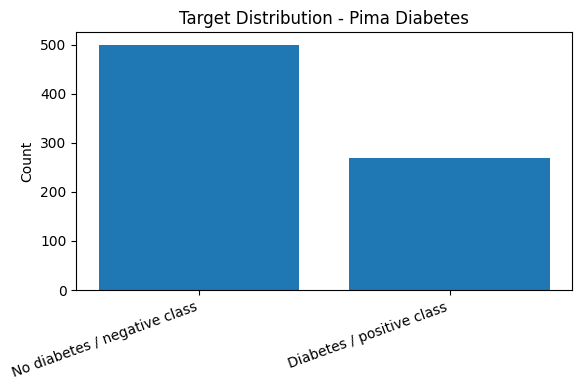

In [30]:
# =========================================================
# 12. Target Distribution
# =========================================================

target_distribution_df = (
    df_raw[target_column]
    .value_counts()
    .sort_index()
    .rename_axis("target_value")
    .reset_index(name="count")
)

target_distribution_df["percentage"] = (
    target_distribution_df["count"] / target_distribution_df["count"].sum() * 100
).round(4)

target_distribution_df["target_label"] = target_distribution_df["target_value"].map({
    0: "No diabetes / negative class",
    1: "Diabetes / positive class"
})

display(target_distribution_df)
save_df(target_distribution_df, "target_distribution.csv")

plt.figure(figsize=(6, 4))
plt.bar(target_distribution_df["target_label"], target_distribution_df["count"])
plt.title("Target Distribution - Pima Diabetes")
plt.ylabel("Count")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(FIGURES_PATH / "target_distribution.png", dpi=300)
plt.show()

In [31]:
# =========================================================
# 13. Outlier Assessment Using IQR
# =========================================================

outlier_rows = []

for col in numeric_features:
    if col == target_column:
        continue

    q1 = df_raw[col].quantile(0.25)
    q3 = df_raw[col].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    n_outliers = int(((df_raw[col] < lower_bound) | (df_raw[col] > upper_bound)).sum())
    outlier_pct = n_outliers / len(df_raw) * 100

    if outlier_pct <= 1:
        outlier_band = "Clean / very low"
    elif outlier_pct <= 5:
        outlier_band = "Mild"
    elif outlier_pct <= 10:
        outlier_band = "Moderate"
    else:
        outlier_band = "High"

    outlier_rows.append({
        "feature": col,
        "q1": q1,
        "q3": q3,
        "iqr": iqr,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "n_outliers": n_outliers,
        "outlier_pct": round(outlier_pct, 4),
        "outlier_band": outlier_band,
        "eda_decision": "Retain for now; preprocessing will use robust methods where appropriate"
    })

outlier_audit_df = pd.DataFrame(outlier_rows)

display(outlier_audit_df)
save_df(outlier_audit_df, "outlier_audit_iqr.csv")

,feature,q1,q3,iqr,lower_bound,upper_bound,n_outliers,outlier_pct,outlier_band,eda_decision
0,Pregnancies,1.00000,6.00000,5.0000,-6.500,13.500,4,0.5208,Clean / very low,Retain for now; preprocessing will use robust ...
1,Glucose,99.00000,140.25000,41.2500,37.125,202.125,5,0.6510,Clean / very low,Retain for now; preprocessing will use robust ...
2,BloodPressure,62.00000,80.00000,18.0000,35.000,107.000,45,5.8594,Moderate,Retain for now; preprocessing will use robust ...
3,SkinThickness,0.00000,32.00000,32.0000,-48.000,80.000,1,0.1302,Clean / very low,Retain for now; preprocessing will use robust ...
4,Insulin,0.00000,127.25000,127.2500,-190.875,318.125,34,4.4271,Mild,Retain for now; preprocessing will use robust ...
5,BMI,27.30000,36.60000,9.3000,13.350,50.550,19,2.4740,Mild,Retain for now; preprocessing will use robust ...
6,DiabetesPedigreeFunction,0.24375,0.62625,0.3825,-0.330,1.200,29,3.7760,Mild,Retain for now; preprocessing will use robust ...
7,Age,24.00000,41.00000,17.0000,-1.500,66.500,9,1.1719,Mild,Retain for now; preprocessing will use robust ...


Saved: /content/drive/MyDrive/Master_Research/07_Results/pima_diabetes/01_manual_eda_pima_diabetes/tables/outlier_audit_iqr.csv


PosixPath('/content/drive/MyDrive/Master_Research/07_Results/pima_diabetes/01_manual_eda_pima_diabetes/tables/outlier_audit_iqr.csv')

In [32]:
# =========================================================
# 14. Feature-Target Summary
# =========================================================

feature_target_rows = []

for col in numeric_features:
    if col == target_column:
        continue

    group_stats = df_raw.groupby(target_column)[col].agg(["mean", "median", "std"]).reset_index()

    negative_stats = group_stats[group_stats[target_column] == 0]
    positive_stats = group_stats[group_stats[target_column] == 1]

    row = {
        "feature": col,
        "mean_target_0": negative_stats["mean"].iloc[0] if not negative_stats.empty else np.nan,
        "mean_target_1": positive_stats["mean"].iloc[0] if not positive_stats.empty else np.nan,
        "median_target_0": negative_stats["median"].iloc[0] if not negative_stats.empty else np.nan,
        "median_target_1": positive_stats["median"].iloc[0] if not positive_stats.empty else np.nan,
    }

    row["mean_difference_target_1_minus_0"] = row["mean_target_1"] - row["mean_target_0"]
    feature_target_rows.append(row)

feature_target_summary_df = pd.DataFrame(feature_target_rows)

display(feature_target_summary_df)
save_df(feature_target_summary_df, "feature_target_summary.csv")

,feature,mean_target_0,mean_target_1,median_target_0,median_target_1,mean_difference_target_1_minus_0
0,Pregnancies,3.298000,4.865672,2.000,4.000,1.567672
1,Glucose,109.980000,141.257463,107.000,140.000,31.277463
2,BloodPressure,68.184000,70.824627,70.000,74.000,2.640627
3,SkinThickness,19.664000,22.164179,21.000,27.000,2.500179
4,Insulin,68.792000,100.335821,39.000,0.000,31.543821
5,BMI,30.304200,35.142537,30.050,34.250,4.838337
6,DiabetesPedigreeFunction,0.429734,0.550500,0.336,0.449,0.120766
7,Age,31.190000,37.067164,27.000,36.000,5.877164


Saved: /content/drive/MyDrive/Master_Research/07_Results/pima_diabetes/01_manual_eda_pima_diabetes/tables/feature_target_summary.csv


PosixPath('/content/drive/MyDrive/Master_Research/07_Results/pima_diabetes/01_manual_eda_pima_diabetes/tables/feature_target_summary.csv')

,feature,correlation_with_target
0,Glucose,0.466581
1,BMI,0.292695
2,Age,0.238356
3,Pregnancies,0.221898
4,DiabetesPedigreeFunction,0.173844
5,Insulin,0.130548
6,SkinThickness,0.074752
7,BloodPressure,0.065068


Saved: /content/drive/MyDrive/Master_Research/07_Results/pima_diabetes/01_manual_eda_pima_diabetes/tables/target_correlations.csv


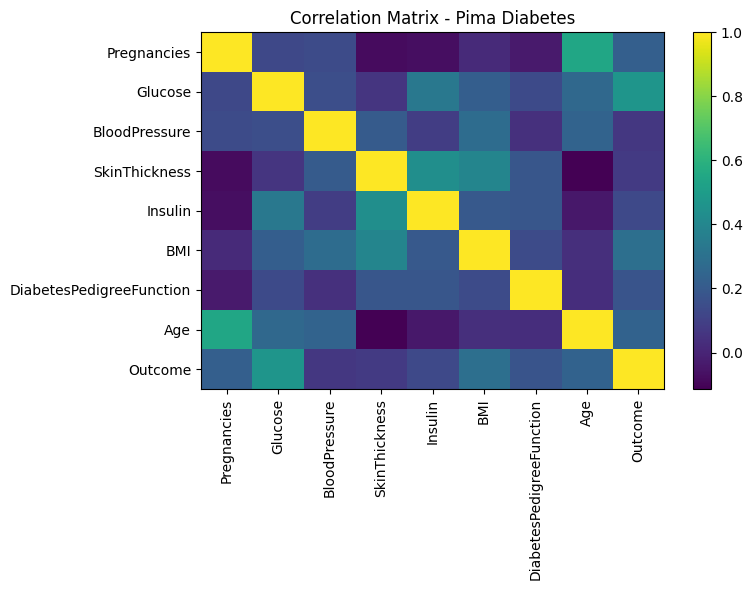

In [33]:
# =========================================================
# 15. Correlation Analysis
# =========================================================

correlation_matrix_df = df_raw[numeric_features].corr()

target_correlation_df = (
    correlation_matrix_df[target_column]
    .drop(target_column)
    .sort_values(key=lambda x: x.abs(), ascending=False)
    .reset_index()
    .rename(columns={"index": "feature", target_column: "correlation_with_target"})
)

display(target_correlation_df)
save_df(target_correlation_df, "target_correlations.csv")
correlation_matrix_df.to_csv(TABLES_PATH / "correlation_matrix.csv")

plt.figure(figsize=(8, 6))
plt.imshow(correlation_matrix_df, aspect="auto")
plt.colorbar()
plt.xticks(range(len(correlation_matrix_df.columns)), correlation_matrix_df.columns, rotation=90)
plt.yticks(range(len(correlation_matrix_df.index)), correlation_matrix_df.index)
plt.title("Correlation Matrix - Pima Diabetes")
plt.tight_layout()
plt.savefig(FIGURES_PATH / "correlation_matrix.png", dpi=300)
plt.show()

## 16. Feature Audit

The feature audit table documents each variable for later preprocessing, explainability, and counterfactual recourse analysis.

This table is important because the downstream EES framework depends on clear assumptions about:

- data type;
- missingness;
- clinical zero values;
- mutability;
- sensitive/proxy-risk status;
- preprocessing requirements;
- interpretation notes.

In [34]:
# =========================================================
# 16. Feature Audit Table
# =========================================================

feature_descriptions = {
    "Pregnancies": "Number of times pregnant",
    "Glucose": "Plasma glucose concentration",
    "BloodPressure": "Diastolic blood pressure",
    "SkinThickness": "Triceps skin fold thickness",
    "Insulin": "2-hour serum insulin",
    "BMI": "Body mass index",
    "DiabetesPedigreeFunction": "Diabetes pedigree function",
    "Age": "Age in years",
    "Outcome": "Diabetes outcome target"
}

immutable_features = ["Age"]
sensitive_features = []
proxy_risk_features = ["Age", "Pregnancies", "DiabetesPedigreeFunction"]
mutable_features = [
    col for col in df_raw.columns
    if col not in immutable_features + [target_column]
]

feature_audit_rows = []

for col in df_raw.columns:
    series = df_raw[col]
    is_numeric = pd.api.types.is_numeric_dtype(series)

    zero_missing_flag = col in zero_impossible_features
    n_clinical_zero = int((series == 0).sum()) if zero_missing_flag else 0
    clinical_zero_pct = round(n_clinical_zero / len(df_raw) * 100, 4) if zero_missing_flag else 0

    feature_audit_rows.append({
        "feature": col,
        "feature_description": feature_descriptions.get(col, "Dataset feature"),
        "role": "target" if col == target_column else "predictor",
        "data_type": str(series.dtype),
        "feature_content": (
            f"min={series.min()}, median={series.median()}, max={series.max()}"
            if is_numeric else
            ", ".join(map(str, sorted(series.dropna().unique().tolist())[:20]))
        ),
        "missing_pct": round(series.isna().mean() * 100, 4),
        "clinical_zero_missing_indicator": zero_missing_flag,
        "clinical_zero_pct": clinical_zero_pct,
        "unique_values": series.nunique(dropna=False),
        "skewness": round(series.skew(), 4) if is_numeric else np.nan,
        "sensitive": col in sensitive_features,
        "proxy_risk": col in proxy_risk_features,
        "mutable": col in mutable_features,
        "expected_preprocessing": (
            "Target variable; no feature preprocessing"
            if col == target_column else
            "Treat zero as missing, impute, then scale"
            if zero_missing_flag else
            "Scale numeric feature"
            if is_numeric else
            "Encode categorical feature"
        ),
        "notes": (
            "Clinically implausible zero values require preprocessing treatment"
            if zero_missing_flag else
            "Target variable"
            if col == target_column else
            "Potential proxy-risk feature; interpret carefully"
            if col in proxy_risk_features else
            "Standard numeric predictor"
        )
    })

feature_audit_df = pd.DataFrame(feature_audit_rows)

display(feature_audit_df)
save_df(feature_audit_df, "feature_audit_table.csv")

,feature,feature_description,role,data_type,feature_content,missing_pct,clinical_zero_missing_indicator,clinical_zero_pct,unique_values,skewness,sensitive,proxy_risk,mutable,expected_preprocessing,notes
0,Pregnancies,Number of times pregnant,predictor,int64,"min=0, median=3.0, max=17",0.0,False,0.0000,17,0.9017,False,True,True,Scale numeric feature,Potential proxy-risk feature; interpret carefully
1,Glucose,Plasma glucose concentration,predictor,int64,"min=0, median=117.0, max=199",0.0,True,0.6510,136,0.1738,False,False,True,"Treat zero as missing, impute, then scale",Clinically implausible zero values require pre...
2,BloodPressure,Diastolic blood pressure,predictor,int64,"min=0, median=72.0, max=122",0.0,True,4.5573,47,-1.8436,False,False,True,"Treat zero as missing, impute, then scale",Clinically implausible zero values require pre...
3,SkinThickness,Triceps skin fold thickness,predictor,int64,"min=0, median=23.0, max=99",0.0,True,29.5573,51,0.1094,False,False,True,"Treat zero as missing, impute, then scale",Clinically implausible zero values require pre...
4,Insulin,2-hour serum insulin,predictor,int64,"min=0, median=30.5, max=846",0.0,True,48.6979,186,2.2723,False,False,True,"Treat zero as missing, impute, then scale",Clinically implausible zero values require pre...
5,BMI,Body mass index,predictor,float64,"min=0.0, median=32.0, max=67.1",0.0,True,1.4323,248,-0.4290,False,False,True,"Treat zero as missing, impute, then scale",Clinically implausible zero values require pre...
6,DiabetesPedigreeFunction,Diabetes pedigree function,predictor,float64,"min=0.078, median=0.3725, max=2.42",0.0,False,0.0000,517,1.9199,False,True,True,Scale numeric feature,Potential proxy-risk feature; interpret carefully
7,Age,Age in years,predictor,int64,"min=21, median=29.0, max=81",0.0,False,0.0000,52,1.1296,False,True,False,Scale numeric feature,Potential proxy-risk feature; interpret carefully
8,Outcome,Diabetes outcome target,target,int64,"min=0, median=0.0, max=1",0.0,False,0.0000,2,0.6350,False,False,False,Target variable; no feature preprocessing,Target variable


Saved: /content/drive/MyDrive/Master_Research/07_Results/pima_diabetes/01_manual_eda_pima_diabetes/tables/feature_audit_table.csv


PosixPath('/content/drive/MyDrive/Master_Research/07_Results/pima_diabetes/01_manual_eda_pima_diabetes/tables/feature_audit_table.csv')

In [35]:
# =========================================================
# 17. Assumptions Register
# =========================================================

assumptions_df = pd.DataFrame([
    {
        "area": "Target definition",
        "assumption": "Outcome is treated as the binary target where 1 indicates diabetes and 0 indicates no diabetes.",
        "reason": "This is the standard target coding used in the Pima Diabetes dataset.",
        "downstream_impact": "Positive class represents clinical risk."
    },
    {
        "area": "Clinical zero values",
        "assumption": "Zeros in Glucose, BloodPressure, SkinThickness, Insulin and BMI are treated as missingness indicators.",
        "reason": "These variables cannot realistically be zero for living patients.",
        "downstream_impact": "Notebook 02 should impute these values before modelling."
    },
    {
        "area": "Pregnancies",
        "assumption": "Zero is valid for Pregnancies.",
        "reason": "A patient can have zero pregnancies.",
        "downstream_impact": "Do not treat zero pregnancies as missing."
    },
    {
        "area": "Outliers",
        "assumption": "Outliers are retained during EDA.",
        "reason": "Clinical measurements may contain important risk information.",
        "downstream_impact": "Robust scaling may be preferred during preprocessing."
    },
    {
        "area": "Mutability",
        "assumption": "Age is non-mutable; most clinical measurements are treated as potentially mutable or clinically manageable.",
        "reason": "Counterfactual recourse should avoid impossible changes.",
        "downstream_impact": "DiCE/actionability should restrict immutable variables later."
    },
    {
        "area": "Proxy risk",
        "assumption": "Age, Pregnancies and DiabetesPedigreeFunction are flagged for proxy-risk awareness.",
        "reason": "These variables may relate to biological, family-history, or demographic risk structures.",
        "downstream_impact": "Interpretability and regulatory sections should discuss proxy-risk limitations."
    }
])

display(assumptions_df)
save_df(assumptions_df, "assumptions_register.csv")

,area,assumption,reason,downstream_impact
0,Target definition,Outcome is treated as the binary target where ...,This is the standard target coding used in the...,Positive class represents clinical risk.
1,Clinical zero values,"Zeros in Glucose, BloodPressure, SkinThickness...",These variables cannot realistically be zero f...,Notebook 02 should impute these values before ...
2,Pregnancies,Zero is valid for Pregnancies.,A patient can have zero pregnancies.,Do not treat zero pregnancies as missing.
3,Outliers,Outliers are retained during EDA.,Clinical measurements may contain important ri...,Robust scaling may be preferred during preproc...
4,Mutability,Age is non-mutable; most clinical measurements...,Counterfactual recourse should avoid impossibl...,DiCE/actionability should restrict immutable v...
5,Proxy risk,"Age, Pregnancies and DiabetesPedigreeFunction ...","These variables may relate to biological, fami...",Interpretability and regulatory sections shoul...


Saved: /content/drive/MyDrive/Master_Research/07_Results/pima_diabetes/01_manual_eda_pima_diabetes/tables/assumptions_register.csv


PosixPath('/content/drive/MyDrive/Master_Research/07_Results/pima_diabetes/01_manual_eda_pima_diabetes/tables/assumptions_register.csv')

In [36]:
# =========================================================
# 18. Save Consolidated EDA Workbook
# =========================================================

eda_outputs = {
    "dataset_overview": overview_df,
    "data_types_missing": dtype_missing_df,
    "clinical_zero_audit": zero_value_df,
    "numeric_summary": numeric_summary_df,
    "target_distribution": target_distribution_df,
    "outlier_audit": outlier_audit_df,
    "feature_target_summary": feature_target_summary_df,
    "target_correlations": target_correlation_df,
    "feature_audit": feature_audit_df,
    "assumptions_register": assumptions_df
}

save_excel(eda_outputs, "manual_eda_pima_diabetes_outputs.xlsx")

Saved: /content/drive/MyDrive/Master_Research/07_Results/pima_diabetes/01_manual_eda_pima_diabetes/tables/manual_eda_pima_diabetes_outputs.xlsx


PosixPath('/content/drive/MyDrive/Master_Research/07_Results/pima_diabetes/01_manual_eda_pima_diabetes/tables/manual_eda_pima_diabetes_outputs.xlsx')

## 19. EDA Interpretation Note

### Simple interpretation

The Pima Diabetes dataset is a binary clinical risk dataset where the target indicates whether a patient has diabetes. The dataset is fully numeric and suitable for machine learning modelling, but several clinical variables contain zero values that are unlikely to be medically valid. These zero values should be treated as missing during preprocessing.

### Technical interpretation

The EDA identifies clinically implausible zero values in key biomedical predictors such as glucose, blood pressure, skin thickness, insulin, and BMI. These values should not be treated as genuine numeric measurements. Instead, they should be converted to missing values and imputed in the preprocessing notebook.

The target distribution should also be monitored because class imbalance may influence model evaluation, especially recall, precision, and business or clinical risk scoring.

### Dissertation contribution

This notebook strengthens the research pipeline by ensuring that the clinical dataset is not treated as a generic numeric table. Instead, domain-aware assumptions are documented before modelling. This supports transparency, traceability, explainability, and regulatory alignment in later EES framework notebooks.